# 03 - Park effects by archetype

**Method:** on balls in play, `woba_gap = actual wOBA - expected wOBA`. Expected wOBA comes from exit velocity and launch angle and does not know the park, so the gap picks up park effects (plus defense, weather, and luck). For each park and archetype we compare the gap to the league-wide gap for the same archetype, then shrink small samples toward zero.

`pitcher_edge` is positive when a park helps that archetype.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED, INTERIM, FIGURES
from src.park_effects import contact_frame, park_archetype_effects, best_archetypes
from src.plots import plot_park_archetypes

df = pd.read_parquet(INTERIM / "pitches_archetyped.parquet")
contact = contact_frame(df)
print(f"{len(contact):,} balls in play")

611,324 balls in play


In [2]:
effects = park_archetype_effects(contact, by_hand=True, shrink_k=200)
effects.to_csv(PROCESSED / "park_archetype_effects.csv", index=False)
effects.head()

,park,archetype,p_throws,bip,gap,hr_rate,gb_rate,lg_gap,lg_hr_rate,lg_gb_rate,effect_raw,effect,pitcher_edge,hr_diff,gb_diff
0,American Family Field,Changeup | higher slot | high-IVB,L,269,0.065174,0.048327,0.434944,0.007615,0.038555,0.454146,0.057559,0.033013,-0.033013,0.009772,-0.019201
1,American Family Field,Changeup | higher slot | high-IVB,R,381,0.010524,0.057743,0.464567,0.011579,0.045239,0.437448,-0.001054,-0.000691,0.000691,0.012504,0.027119
2,American Family Field,Changeup | higher slot | low-IVB,L,121,0.018192,0.008264,0.628099,0.017305,0.023092,0.581907,0.000887,0.000335,-0.000335,-0.014827,0.046192
3,American Family Field,Changeup | higher slot | low-IVB,R,159,0.04602,0.031447,0.616352,0.01144,0.032729,0.553449,0.03458,0.015315,-0.015315,-0.001283,0.062904
4,American Family Field,Changeup | lower slot | high-IVB,L,84,0.013852,0.047619,0.392857,0.010778,0.045419,0.431609,0.003074,0.000909,-0.000909,0.002200,-0.038752


## Check cell sizes

Each row of `effects` is one park/archetype/handedness cell. Cells with few balls in play are noisy (they are shrunk toward zero, and the charts hide cells under 100). If most cells are small, use fewer archetype tiers or more seasons.

In [3]:
print(effects["bip"].describe().round(0))
print(f"Cells with 100+ balls in play: {(effects['bip'] >= 100).mean():.0%}")

count    2039.0
mean      300.0
std       323.0
min         1.0
25%        96.0
50%       200.0
75%       387.0
max      2393.0
Name: bip, dtype: Float64
Cells with 100+ balls in play: 74%


## Sanity check: park-level ranking

Average gap by park, in wOBA points. Compare this ranking to the park factors leaderboard on Baseball Savant. It should line up broadly (Coors Field near the top, for example). If it looks wrong, fix the data or park labels before going further.

In [4]:
(contact.groupby("park")["woba_gap"].mean() * 1000).sort_values(ascending=False).round(1)

park
Sutter Health Park              50.6
Coors Field                     43.3
Great American Ball Park        27.4
Citizens Bank Park              24.9
Fenway Park                     24.3
George M. Steinbrenner Field    20.0
Daikin Park                     15.6
Tropicana Field                 12.7
American Family Field           11.6
Dodger Stadium                  10.8
Target Field                    10.2
Angel Stadium                   10.1
Rogers Centre                    8.8
Chase Field                      8.2
loanDepot park                   6.8
Nationals Park                   6.5
Truist Park                      6.5
Oracle Park                      5.8
Rate Field                       5.5
Wrigley Field                    5.5
Progressive Field                4.8
Oakland Coliseum                 4.2
Comerica Park                    3.7
Oriole Park at Camden Yards      2.7
PNC Park                         1.9
Globe Life Field                 1.0
Citi Field                      -

In [5]:
chk = pd.read_parquet(INTERIM / "pitches_archetyped.parquet", columns=["game_year", "home_team", "park"])
chk[chk["park"].isin(["Sutter Health Park", "Oakland Coliseum"])].groupby(["game_year", "home_team", "park"]).size()

game_year  home_team  park              
2022       ATH        Oakland Coliseum      23084
2023       ATH        Oakland Coliseum      24152
2024       ATH        Oakland Coliseum      23482
2025       ATH        Sutter Health Park    24430
2026       ATH        Sutter Health Park    24601
dtype: int64

## Robustness: split-half stability

Compute effects separately on the earlier and later seasons. If the effects are real, they should be positively correlated. Report this number on your methodology slide, whatever it turns out to be.

In [6]:
seasons = sorted(contact["game_year"].unique())
half = len(seasons) // 2
a = park_archetype_effects(contact[contact["game_year"].isin(seasons[:half])])
b = park_archetype_effects(contact[contact["game_year"].isin(seasons[half:])])
m = a.merge(b, on=["park", "archetype", "p_throws"], suffixes=("_a", "_b"))
m = m[(m["bip_a"] >= 100) & (m["bip_b"] >= 100)]
print(f"{len(m)} park/archetype cells, correlation: {m['effect_raw_a'].corr(m['effect_raw_b']):.2f}")

782 park/archetype cells, correlation: 0.10


## Example park

In [7]:
best_archetypes(effects, "Coors Field", hand="R")

,park,archetype,p_throws,bip,gap,hr_rate,gb_rate,lg_gap,lg_hr_rate,lg_gb_rate,effect_raw,effect,pitcher_edge,hr_diff,gb_diff
495,Coors Field,Splitter | higher slot | high-IVB,R,185,0.008555,0.043243,0.432432,0.025434,0.041574,0.485919,-0.016879,-0.008111,0.008111,0.001670,-0.053486
501,Coors Field,Splitter | lower slot | low-IVB,R,101,-0.01243,0.000000,0.534653,-0.007068,0.025185,0.591045,-0.005362,-0.001799,0.001799,-0.025185,-0.056392
463,Coors Field,Cutter | higher slot | high-IVB,R,125,0.001959,0.024000,0.368000,0.005171,0.044192,0.408679,-0.003212,-0.001235,0.001235,-0.020192,-0.040679
449,Coors Field,Changeup | higher slot | low-IVB,R,297,0.021231,0.037037,0.505051,0.01144,0.032729,0.553449,0.009791,0.005851,-0.005851,0.004308,-0.048398
467,Coors Field,Cutter | lower slot | high-IVB,R,118,0.022851,0.059322,0.245763,0.00602,0.049265,0.349160,0.016831,0.006246,-0.006246,0.010057,-0.103397


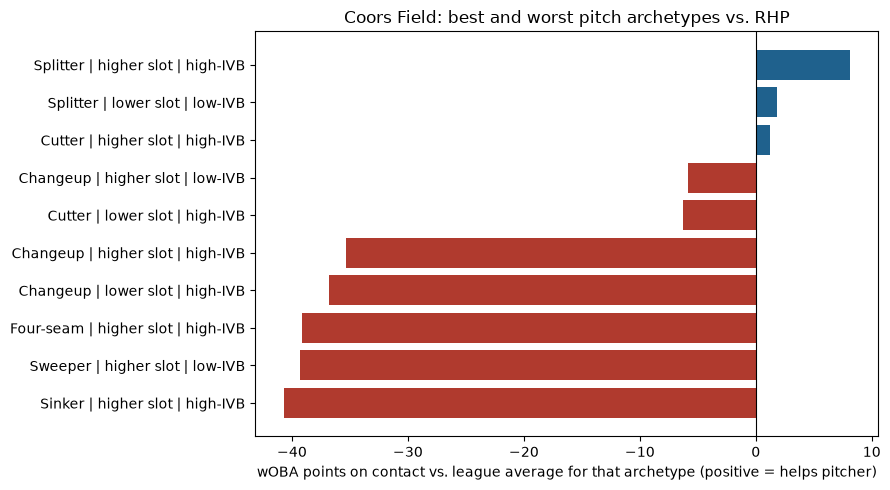

In [8]:
plot_park_archetypes(effects, "Coors Field", "R", path=FIGURES / "Coors_Field_RHP.png")
plt.show()

## Make a chart for every park

In [9]:
for park in sorted(effects["park"].unique()):
    for hand in ["R", "L"]:
        fig = plot_park_archetypes(effects, park, hand, path=FIGURES / f"{park.replace(' ', '_')}_{hand}HP.png")
        if fig is not None:
            plt.close(fig)

## Commit

```
git add notebooks/03_park_effects.ipynb data/processed/park_archetype_effects.csv slides/figures
git commit -m "park effects by archetype with stability check"
git push
```